## Ambient f--k spectra of each cable leg

Conventional (Bartlett) f--k beamforming of the two legs of the PISCES-25 hairpin
cable, on the 5 Hz decimated hourly files, over the 30 min block starting
2025-04-26 00:00 UTC.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from das_tools.utils import proj_path
from das_tools.readers import decimated
from das_tools.processing import pisces25, spectral
from das_tools.processing.filtering import filter_channels
from das_tools.physics import dispersion_relations as dr

plt.rcParams.update({
    "font.size": 18,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})
mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{times}",
})

Configuration

In [2]:
DAS_DIR = proj_path.hourly_das_dir()
CH_GEO_FILE = proj_path.data_dir("channel_geometry_20260908_L.npz")
FIG_DIR = proj_path.figures_dir("supplementary", "S10_legwise_fk_plot")

# 180 s snapshots, averaged over a 30 min covariance block
BLOCK_START = pd.Timestamp("2025-04-26 00:00:00")   # tz-naive UTC, as the hourly index
WINDOW_S = 180.0
AVG_S = 30 * 60.0

# Band and wavenumber grid. k is signed so both directions along a leg show up.
FMIN, FMAX = 0.1, 1.0
KMIN, KMAX, NK = -0.25, 0.25, 251
K_GRID = np.linspace(KMIN, KMAX, NK)

FILTER_ORDER = 4

Load the block and register the channels to their real positions

In [3]:
hourly_map = decimated.index_hourly_files(DAS_DIR)
loaded = decimated.load_block(hourly_map, BLOCK_START, BLOCK_START + pd.Timedelta(seconds=AVG_S))
if loaded is None:
    raise FileNotFoundError(f"no complete block at {BLOCK_START} in {DAS_DIR}")
x, channel, fs = loaded                        # channel: signed offset from the elbow

ch_xy, m1 = pisces25.load_leg_geometry(CH_GEO_FILE, channel)   # (2, M), leg 1 = first m1

x = filter_channels(x.astype(float), fs=fs, fmin=FMIN, fmax=FMAX,
                    order=FILTER_ORDER, zero_phase=True)

print(f"fs = {fs} Hz, channels {channel.min()}..{channel.max()}, block {x.shape}")

fs = 5.0 Hz, channels -45..44, block (9000, 90)


## Split into legs and project onto each leg's own axis

Leg 1 is the pre-elbow side (`channel < 0`), leg 2 the post-elbow side (`channel >= 0`,
so the apex channel itself is counted with leg 2).

**Sign convention.** Each leg's channels are ordered starting at the apex before the axis
is fitted (leg 1 is reversed for this), and $\hat{d}$ is flipped to point from the first
channel to the last -- i.e. **$+\hat{d}$ points away from the elbow on both legs**. With
$a_m(k) = \exp(-jk\,\hat{d}\cdot\mathbf{x}_m)$ and the $e^{-j\omega t}$ FFT kernel, the
beamformer peaks at the $k$ of the wave's own wavevector, so

> **$k > 0$ = energy propagating away from the elbow; $k < 0$ = energy propagating toward
> the elbow.**

In [4]:
def leg_axis(xy):
    '''Leading principal direction of a leg and the channel coordinate along it.

    Returns (d, s, resid_rms): unit vector, projected coordinate (m, zero-mean),
    and the rms distance of the channels off that axis.
    '''
    c = xy - xy.mean(axis=1, keepdims=True)
    u, _, _ = np.linalg.svd(c, full_matrices=False)
    d = u[:, 0]
    if d @ (xy[:, -1] - xy[:, 0]) < 0:      # point away from the elbow
        d = -d
    s = d @ c
    resid = c - np.outer(d, s)
    return d, s, float(np.sqrt((resid ** 2).sum(axis=0).mean()))


# Leg 1 runs toward the elbow in channel order; reverse it so both legs start at the apex.
leg_slices = {"Leg 1": slice(m1 - 1, None, -1), "Leg 2": slice(m1, None)}
legs = {}
for name, sl in leg_slices.items():
    xy = ch_xy[:, sl]
    d, s, resid_rms = leg_axis(xy)
    spacing = np.diff(np.sort(s))
    legs[name] = {"sl": sl, "xy": xy, "d": d, "s": s}
    print(f"{name}: M = {xy.shape[1]:3d}, axis = ({d[0]:+.3f}, {d[1]:+.3f}), "
          f"aperture = {np.ptp(s):6.1f} m, off-axis rms = {resid_rms:4.1f} m, "
          f"projected spacing min/med/max = {spacing.min():.2f}/{np.median(spacing):.2f}/{spacing.max():.2f} m")

Leg 1: M =  45, axis = (+0.176, -0.984), aperture =  141.0 m, off-axis rms =  1.9 m, projected spacing min/med/max = 2.89/3.22/3.23 m
Leg 2: M =  45, axis = (+0.849, +0.528), aperture =  139.8 m, off-axis rms =  1.3 m, projected spacing min/med/max = 3.12/3.18/3.21 m


Averaged snapshot covariance, per leg

In [5]:
n_win = int(round(WINDOW_S * fs))
n_snapshots = int(AVG_S // WINDOW_S)

Rk = {name: 0.0 for name in legs}
n_valid = 0

for i in range(n_snapshots):
    x_win = x[i * n_win:(i + 1) * n_win]
    if np.isnan(x_win).any():
        continue                                   # never FFT across a decimation gap
    X, freq = spectral.bandlimited_windowed_rfft(x_win, fs, FMIN, FMAX)   # (F, M)
    for name, leg in legs.items():
        Xl = X[:, leg["sl"]]                       # channels in step with leg["xy"]
        Rk[name] = Rk[name] + np.einsum("fm,fn->fmn", Xl, Xl.conj())
    n_valid += 1

if n_valid == 0:
    raise RuntimeError("no valid snapshots in this block")
Rk = {name: R / n_valid for name, R in Rk.items()}

print(f"{n_valid}/{n_snapshots} snapshots used, {freq.size} frequency bins "
      f"({freq[0]:.3f}-{freq[-1]:.3f} Hz, df = {freq[1] - freq[0]:.4f} Hz)")

10/10 snapshots used, 163 frequency bins (0.100-1.000 Hz, df = 0.0056 Hz)


### Beamform

$B(f,k) = \mathbf{a}(k)^{H}\,\mathbf{R}(f)\,\mathbf{a}(k)$ with
$a_m(k) = \exp(-jk\,\hat{d}\cdot\mathbf{x}_m)$ evaluated at the real channel positions.

In [6]:
for name, leg in legs.items():
    A = np.exp(-1j * np.outer(leg["s"], K_GRID))            # (M, Nk)
    leg["B"] = np.real(np.einsum("mk,fmn,nk->fk", A.conj(), Rk[name], A))   # (F, Nk)

wrote figures/supplementary/S10_legwise_fk_plot/fk_eachLeg_20250426_0000_180s_30min.png


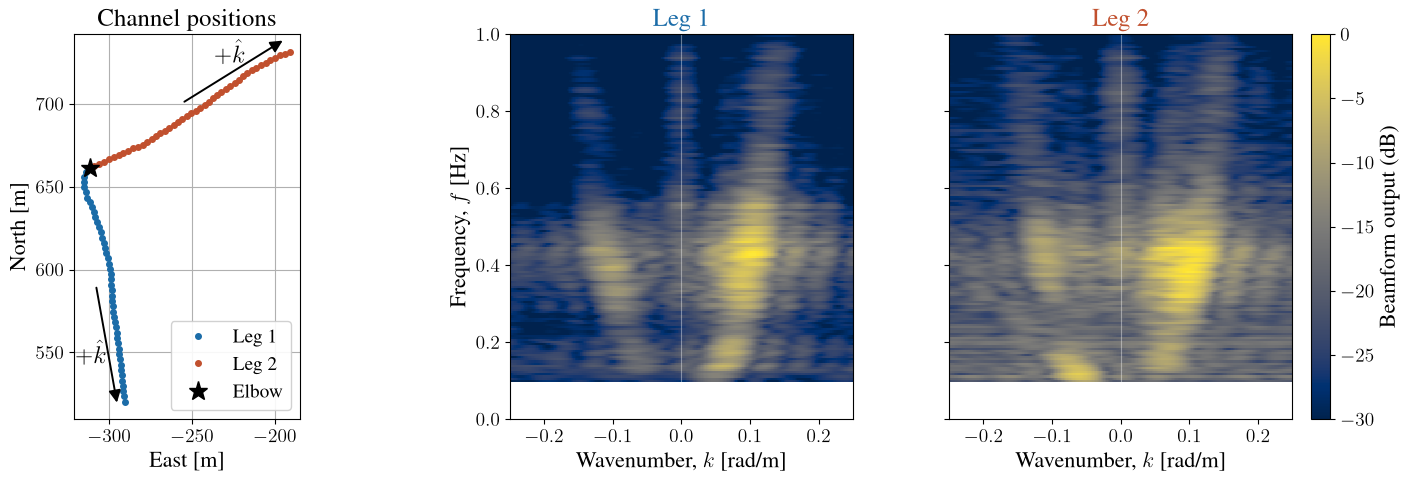

In [7]:
PER_FREQ_NORM = False
SHOW_FG = False
DYN_RANGE = 30.0          # dB below the reference

# Flexural-gravity overlay parameters
E, NU, P = 0.6e9, 0.3, 0.6e6
H_I, H_W = 1.0, 10.0
RHO_I, RHO_W = 900.0, 1000.0

k_fg = dr.fg_disp_eq_ml_c_vec(freq, E, NU, H_I, H_W, RHO_I, RHO_W, P)

leg_colors = dict(zip(legs, ["#1b6ca8", "#c1502e"]))

fig, axs = plt.subplots(1, 3, figsize=(19.0, 5.0), gridspec_kw={"wspace": 0.28})

# --- panel 1: channel positions ---------------------------------------------
# The arrow beside each leg is +d_hat, the direction a k > 0 wave travels in
# the corresponding f--k panel. Both point away from the elbow. The arrows are
# offset outward from the cable so they do not sit on top of the channels.
arrow_offset = 0.10          # perpendicular offset, as a fraction of the half-aperture
ax = axs[0]
centroid = ch_xy.mean(axis=1)
for name, leg in legs.items():
    xy, d = leg["xy"], leg["d"]
    ax.plot(xy[0], xy[1], ".", ms=8, color=leg_colors[name], label=name)

    mid = xy.mean(axis=1)
    half = 0.5 * np.ptp(leg["s"])
    perp = np.array([-d[1], d[0]])
    if perp @ (mid - centroid) < 0:          # push the arrow away from the cable
        perp = -perp
    off = arrow_offset * half * perp
    ax.annotate("", xy=mid + half * d + off, xytext=mid + off,
                arrowprops=dict(arrowstyle="-|>", color="k", lw=1.4,
                                mutation_scale=18, shrinkA=0, shrinkB=0))
    lab = mid + 0.55 * half * d + off + 0.15 * half * perp
    ax.text(lab[0], lab[1], r"$+\hat{k}$", color="k", ha="center", va="center")

ax.plot(*ch_xy[:, channel == 0], "k*", ms=14, label="Elbow")
ax.set_aspect("equal")
ax.set_xlabel(r"East [m]")
ax.set_ylabel(r"North [m]")
ax.set_title("Channel positions")
ax.legend(loc="best", framealpha=0.9)
ax.grid(True)

# --- panels 2-3: f--k of each leg -------------------------------------------
for ax, (name, leg) in zip(axs[1:], legs.items()):
    B = leg["B"]
    ref = B.max(axis=1, keepdims=True) if PER_FREQ_NORM else B.max()
    im = ax.pcolormesh(K_GRID, freq, 10 * np.log10(B / ref), cmap="cividis",
                       vmin=-DYN_RANGE, shading="nearest", rasterized=True)
    ax.axvline(0.0, color="w", lw=0.8, alpha=0.4)

    if SHOW_FG:
        ax.plot(k_fg, freq, color="r", ls="--", lw=2.0, label="FG")
        ax.plot(-k_fg, freq, color="r", ls="--", lw=2.0)

    ax.set_xlim(KMIN, KMAX)
    ax.set_ylim(0.0, FMAX)
    ax.set_xlabel(r"Wavenumber, $k$ [rad/m]")
    ax.set_title(name, color=leg_colors[name])

axs[1].set_ylabel(r"Frequency, $f$ [Hz]")
axs[2].tick_params(labelleft=False)
if SHOW_FG:
    axs[1].legend(loc="upper left", facecolor="#222222", edgecolor="#444444",
                  labelcolor="white")

cbar = fig.colorbar(im, ax=axs[1:], pad=0.02)
cbar.set_label("Beamform output (dB)" + (", per freq." if PER_FREQ_NORM else ""))

out_png = FIG_DIR / f"fk_eachLeg_{BLOCK_START:%Y%m%d_%H%M}_{WINDOW_S:.0f}s_{AVG_S / 60:.0f}min.png"
fig.savefig(out_png, dpi=300, bbox_inches="tight")
print(f"wrote {out_png.relative_to(proj_path.find_project_root())}")

plt.show()